# MSCS 634: Data Mining and Machine Learning
## Lab 5: Hierarchical and DBSCAN Clustering

**Name:** Nikita Metha  
**Course:** MSCS 634: Data Mining and Machine Learning  
**Assignment:** Wine Dataset Clustering with Hierarchical and DBSCAN Methods

## Step 1: Data Preparation and Exploration

In [1]:
# Import data, visualization, clustering, and evaluation tools.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Load the Wine data and place its features and known labels in a DataFrame.
wine = load_wine()
wine_df = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_df["target"] = wine.target
X = wine_df.drop(columns="target")
y = wine_df["target"]

print(f"Dataset shape: {wine_df.shape}")
print(f"Class distribution: {y.value_counts().sort_index().to_dict()}")

Dataset shape: (178, 14)
Class distribution: {0: 59, 1: 71, 2: 48}


### Explore the Dataset

In [2]:
# Inspect rows, types, distributions, and missing values before clustering.
# Keep the known target labels separate: they are for evaluation, not model input.
display(wine_df.head())
print("\nDataset information:")
wine_df.info()
print("\nDescriptive statistics:")
display(wine_df.describe().T)
print("\nMissing values:")
display(wine_df.isna().sum())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



Missing values:


alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

### Standardize Features

In [3]:
# Wine features have very different ranges (for example, proline is in the thousands, hue near 1).
# StandardScaler applies z = (value - feature mean) / feature standard deviation so ranges are comparable.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Check the result: each feature should have mean near 0 and population standard deviation near 1.
display(X_scaled_df.head())
print("Scaled feature means (approximately 0):")
display(X_scaled_df.mean().round(6).to_frame("mean").T)
print("Scaled feature standard deviations:")
display(X_scaled_df.std(ddof=0).round(6).to_frame("std").T)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Scaled feature means (approximately 0):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0


Scaled feature standard deviations:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### Why Standardization Matters

**Dataset structure:** The Wine data has 178 rows and 13 numeric chemical features (no missing values, all `float64`), plus a `target` column with three known wine classes. The target is kept out of the clustering input and is used only afterward for homogeneity and completeness.

**Why scale:** The features are on very different scales. `proline` ranges from 278 to 1680 (std about 315) and `magnesium` averages about 100 (std about 14), while `hue` averages about 0.96 (std about 0.23) and `nonflavanoid_phenols` about 0.36 (std about 0.12). Agglomerative clustering (Ward) and DBSCAN both rely on Euclidean distance, so unscaled `proline` would dominate nearly every distance and the other features would barely matter.

**Result:** After `StandardScaler`, every feature has a mean of 0 and a standard deviation of 1, as the check above confirms. All 13 features now contribute comparably to the distance calculations.

## Step 2: Hierarchical Clustering

In [4]:
# Fit Ward-linkage hierarchical models for several requested cluster counts.
hierarchical_clusters = {}
hierarchical_rows = []

for n_clusters in [2, 3, 4, 5]:
    # Ward linkage merges groups while minimizing the increase in within-cluster variance.
    model = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
    labels = model.fit_predict(X_scaled)
    hierarchical_clusters[n_clusters] = labels

    # Calculate quality metrics using all standardized features and known labels only for evaluation.
    silhouette = silhouette_score(X_scaled, labels)
    homogeneity = homogeneity_score(y, labels)
    completeness = completeness_score(y, labels)
    hierarchical_rows.append({
        "algorithm": "Agglomerative",
        "parameter": f"n_clusters={n_clusters}",
        "n_clusters": len(np.unique(labels)),
        "noise_points": 0,
        "silhouette_score": silhouette,
        "homogeneity_score": homogeneity,
        "completeness_score": completeness,
    })

# Store all hierarchical configurations together for comparison.
hierarchical_results = pd.DataFrame(hierarchical_rows)
display(hierarchical_results.round(4))

,algorithm,parameter,n_clusters,noise_points,silhouette_score,homogeneity_score,completeness_score
0,Agglomerative,n_clusters=2,2,0,0.2670,0.4441,0.7745
1,Agglomerative,n_clusters=3,3,0,0.2774,0.7904,0.7825
2,Agglomerative,n_clusters=4,4,0,0.2258,0.7904,0.6490
3,Agglomerative,n_clusters=5,5,0,0.1867,0.8106,0.5762


### PCA Projection for Hierarchical Cluster Visualization

PCA variance explained by PC1 and PC2: 55.4%


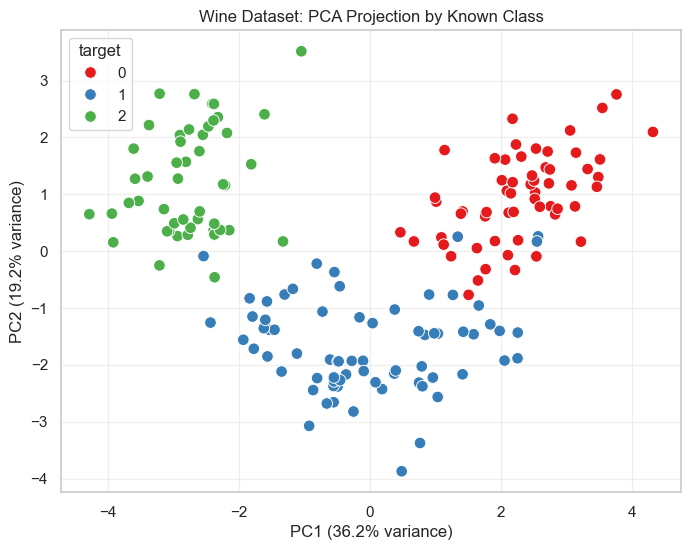

In [5]:
# Cluster models use all 13 scaled features; PCA only compresses them for two-dimensional plots.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["target"] = y.to_numpy()

# Each variance ratio is the fraction of total standardized-data variance retained by that component.
print(f"PCA variance explained by PC1 and PC2: {pca.explained_variance_ratio_.sum():.1%}")

# Show known classes for context only; these labels are not passed into the clustering algorithms.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="target", palette="Set1", s=70)
plt.title("Wine Dataset: PCA Projection by Known Class")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.grid(True, alpha=0.3)
plt.show()

### Compare Hierarchical Cluster Counts

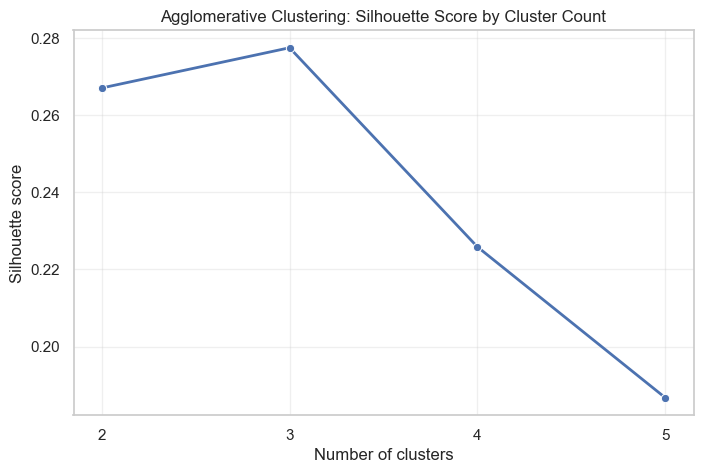

Best hierarchical configuration by silhouette score: n_clusters=3
Best hierarchical silhouette score: 0.2774


In [6]:
# Silhouette ranges from -1 to 1; higher values mean stronger within-cluster cohesion and between-cluster separation.
# Plot it across cluster counts to see how the number of groups affects separation.
plt.figure(figsize=(8, 5))
sns.lineplot(data=hierarchical_results, x="n_clusters", y="silhouette_score", marker="o", linewidth=2)
plt.title("Agglomerative Clustering: Silhouette Score by Cluster Count")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.xticks([2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.show()

# Choose the tested cluster count with the maximum silhouette; compare other metrics and plots too.
best_hierarchical_n = int(hierarchical_results.loc[hierarchical_results["silhouette_score"].idxmax(), "n_clusters"])
best_hierarchical_score = hierarchical_results["silhouette_score"].max()
print(f"Best hierarchical configuration by silhouette score: n_clusters={best_hierarchical_n}")
print(f"Best hierarchical silhouette score: {best_hierarchical_score:.4f}")

### How to Read the Hierarchical Results

- **Silhouette** peaks at `n_clusters=3` (0.2774) and falls at 4 (0.2258) and 5 (0.1867), so three groups give the best cohesion and separation. The score at 2 clusters (0.2670) is close, which shows that two of the groups are much closer to each other than to the third.
- **Homogeneity** (each cluster holds mostly one wine class) is 0.7904 at 3 clusters, unchanged at 4, and 0.8106 at 5. **Completeness** (each class stays in one cluster) drops from 0.7825 at 3 clusters to 0.6490 at 4 and 0.5762 at 5. Extra splits therefore add little purity but break known classes apart.
- At 2 clusters, homogeneity is low (0.4441) because two classes are forced into one cluster.
- Taken together, `n_clusters=3` is the best balance of separation and class agreement, and it matches the three known wine classes even though the labels were never used for fitting.
- The PCA plots below show the same pattern. PC1 and PC2 keep only 55.4% of the variance, so some overlap between clusters in 2D comes from the projection rather than from the clustering.

### Scatter Plots of Hierarchical Clusters

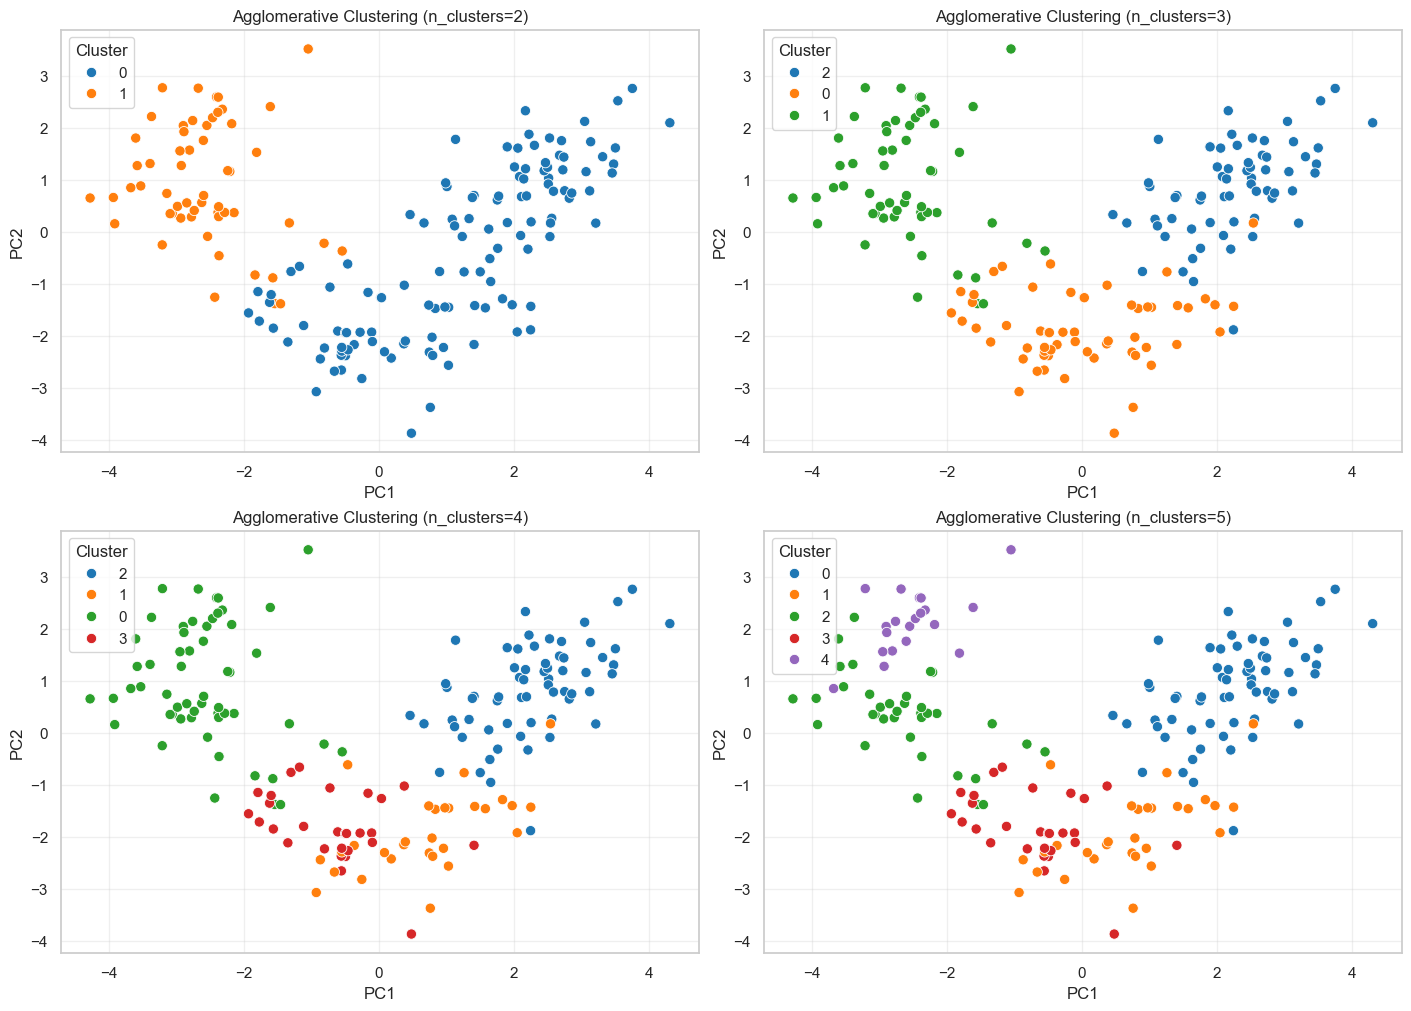

In [7]:
# Show each hierarchical labeling on the same PCA coordinate system.
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, n_clusters in zip(axes.ravel(), [2, 3, 4, 5]):
    plot_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
    plot_df["cluster"] = hierarchical_clusters[n_clusters].astype(str)
    sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="cluster", palette="tab10", s=55, ax=ax)
    ax.set_title(f"Agglomerative Clustering (n_clusters={n_clusters})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Cluster", loc="best")
plt.show()

### Generate and Interpret a Dendrogram

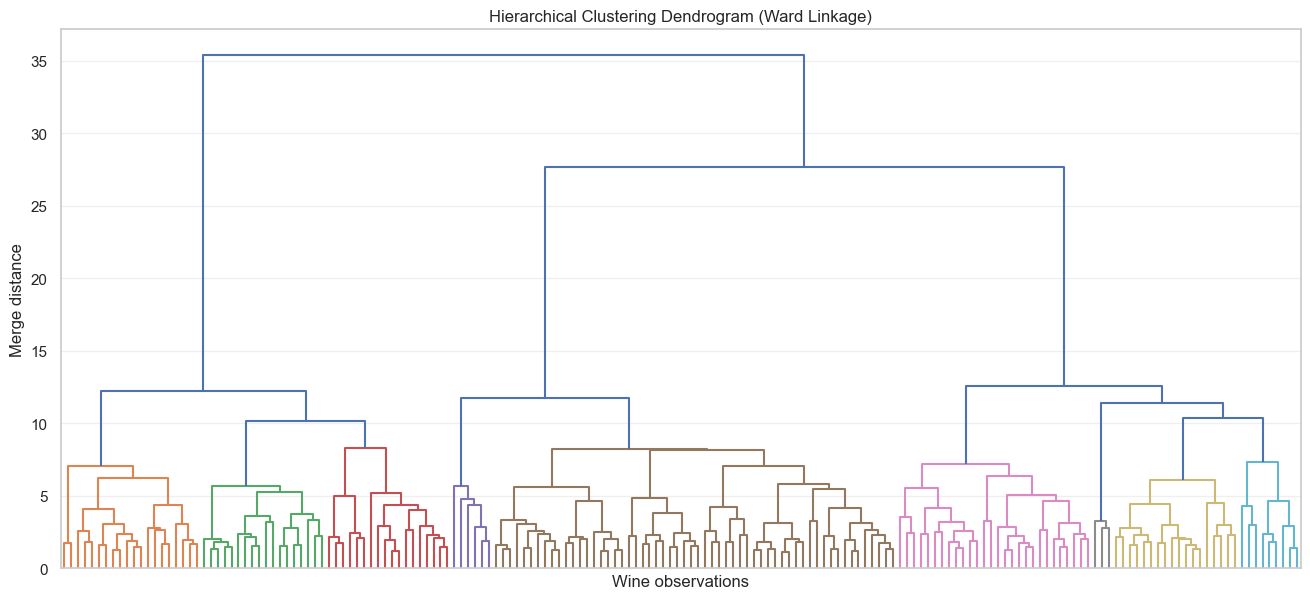

In [8]:
# Ward linkage stores each merge, its distance, and merged-group size in this matrix.
linkage_matrix = linkage(X_scaled, method="ward")
plt.figure(figsize=(16, 7))
dendrogram(linkage_matrix, no_labels=True, color_threshold=10)
# Larger vertical merge jumps suggest candidate horizontal cuts and cluster boundaries.
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Wine observations")
plt.ylabel("Merge distance")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

**Dendrogram interpretation:** The y-axis is the Ward merge distance, and a horizontal cut at a given height gives that many clusters. The top merge happens at a distance of about 35 and the next at about 28. A cut anywhere between roughly 12.5 and 28 crosses three branches, so the dendrogram supports three clusters, consistent with the silhouette peak at `n_clusters=3`. Cutting above 28 gives two clusters. Cutting below 12 splits the data into many small groups (the colored branches at `color_threshold=10`), which are finer than the data supports. The large gap between the 3-cluster cut and the lower merges shows that the three main groups are well separated.

## Step 3: DBSCAN Clustering

In [9]:
def evaluate_labels(labels, features=X_scaled, targets=y):
    # DBSCAN uses -1 for noise; exclude those rows from cluster-quality calculations.
    non_noise = labels != -1
    cluster_labels = set(labels[non_noise])
    cluster_count = len(cluster_labels)
    noise_count = int((labels == -1).sum())

    # Silhouette averages cohesion versus separation and needs at least two clusters.
    if cluster_count >= 2:
        silhouette = silhouette_score(features[non_noise], labels[non_noise])
    else:
        silhouette = np.nan

    # Homogeneity compares each cluster to the known classes.
    # Completeness checks whether each known class stays together in one cluster.
    if cluster_count >= 1:
        homogeneity = homogeneity_score(targets[non_noise], labels[non_noise])
        completeness = completeness_score(targets[non_noise], labels[non_noise])
    else:
        homogeneity = np.nan
        completeness = np.nan

    return {
        "n_clusters": cluster_count,
        "noise_points": noise_count,
        "silhouette_score": silhouette,
        "homogeneity_score": homogeneity,
        "completeness_score": completeness,
    }

# Fit one initial DBSCAN model and count its non-noise clusters and noise observations.
initial_dbscan = DBSCAN(eps=2.0, min_samples=5)
initial_labels = initial_dbscan.fit_predict(X_scaled)
initial_metrics = evaluate_labels(initial_labels)
print(f"Initial DBSCAN configuration: eps=2.0, min_samples=5")
print(f"Clusters: {initial_metrics['n_clusters']}; noise points: {initial_metrics['noise_points']}")

Initial DBSCAN configuration: eps=2.0, min_samples=5
Clusters: 5; noise points: 85


### Experiment with DBSCAN Parameters

In [10]:
# eps is the neighborhood radius; min_samples is the neighbor count needed for a core point.
eps_values = [1.2, 1.5, 1.8, 2.0, 2.3, 2.6]
min_samples_values = [3, 5, 8]
dbscan_rows = []
dbscan_labels = {}

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)
        metrics = evaluate_labels(labels)
        key = (eps, min_samples)
        dbscan_labels[key] = labels
        dbscan_rows.append({
            "algorithm": "DBSCAN",
            "parameter": f"eps={eps}, min_samples={min_samples}",
            "eps": eps,
            "min_samples": min_samples,
            **metrics,
        })

# Wider eps can connect observations into larger groups; higher min_samples can create more noise.
# Keep all parameter combinations so those effects can be compared in the table and plots.
dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round(4))

,algorithm,parameter,eps,min_samples,n_clusters,noise_points,silhouette_score,homogeneity_score,completeness_score
0,DBSCAN,"eps=1.2, min_samples=3",1.2,3,0,178,NaN,NaN,NaN
1,DBSCAN,"eps=1.2, min_samples=5",1.2,5,0,178,NaN,NaN,NaN
2,DBSCAN,"eps=1.2, min_samples=8",1.2,8,0,178,NaN,NaN,NaN
3,DBSCAN,"eps=1.5, min_samples=3",1.5,3,8,147,0.3311,1.0000,0.4319
4,DBSCAN,"eps=1.5, min_samples=5",1.5,5,0,178,NaN,NaN,NaN
5,DBSCAN,"eps=1.5, min_samples=8",1.5,8,0,178,NaN,NaN,NaN
6,DBSCAN,"eps=1.8, min_samples=3",1.8,3,8,90,0.3116,1.0000,0.6225
7,DBSCAN,"eps=1.8, min_samples=5",1.8,5,7,118,0.2462,1.0000,0.5635
8,DBSCAN,"eps=1.8, min_samples=8",1.8,8,1,170,NaN,1.0000,1.0000
9,DBSCAN,"eps=2.0, min_samples=3",2.0,3,5,64,0.2113,0.5801,0.6273


### DBSCAN Parameter Interpretation

- **Small `eps` gives only noise.** At `eps=1.2` all 178 points are noise for every `min_samples`. At `eps=1.5` only `min_samples=3` forms clusters (8 clusters, 147 noise points). In 13 dimensions, points are far apart, so the neighborhood radius must be fairly large.
- **Larger `eps` merges groups.** With `min_samples=5`, the result goes from no clusters at 1.5 to 7 clusters at 1.8, 5 at 2.0, 2 at 2.3, and a single cluster at 2.6. At `eps=2.6` the clustering is not useful (homogeneity 0.0, silhouette undefined).
- **Larger `min_samples` creates more noise.** At `eps=2.0`, noise rises from 64 (`min_samples=3`) to 85 (5) to 117 (8), and the cluster count falls from 5 to 3.
- **Best silhouette:** 0.4360 at `eps=2.0`, `min_samples=8` (homogeneity 0.8998, completeness 0.9320). However, 117 of 178 points (about 66%) are noise, so these scores describe only 61 points.
- **Better coverage:** `eps=2.3`, `min_samples=5` has 2 clusters and 42 noise points (silhouette 0.3307, homogeneity 0.5345, completeness 0.9438). More points are clustered, but two of the wine classes are merged.
- **Caveat:** Metrics exclude noise, so DBSCAN scores must be read together with the noise count. Silhouette is undefined (`NaN`) with fewer than two clusters.
- **Misleading perfect scores:** At `eps=1.8, min_samples=8` the single cluster has homogeneity and completeness of 1.0, but 170 of 178 points are noise, so only 8 points are scored. A single cluster is trivially homogeneous and complete, so this result is not meaningful.

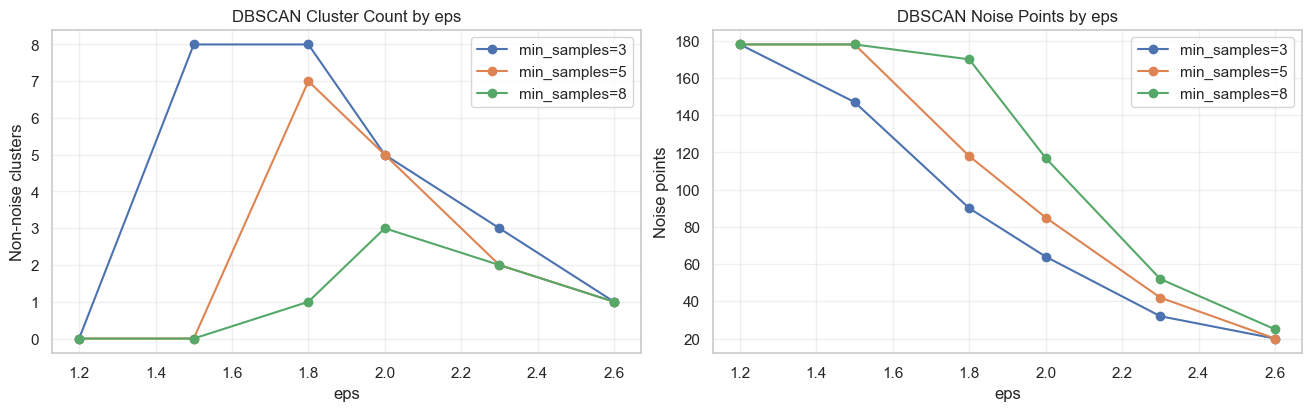

In [11]:
# Plot how eps changes cluster count and noise for each min_samples setting.
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for min_samples in min_samples_values:
    subset = dbscan_results[dbscan_results["min_samples"] == min_samples]
    axes[0].plot(subset["eps"], subset["n_clusters"], marker="o", label=f"min_samples={min_samples}")
    axes[1].plot(subset["eps"], subset["noise_points"], marker="o", label=f"min_samples={min_samples}")

axes[0].set_title("DBSCAN Cluster Count by eps")
axes[0].set_xlabel("eps")
axes[0].set_ylabel("Non-noise clusters")
axes[1].set_title("DBSCAN Noise Points by eps")
axes[1].set_xlabel("eps")
axes[1].set_ylabel("Noise points")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.show()

### Visualize DBSCAN Clusters and Noise

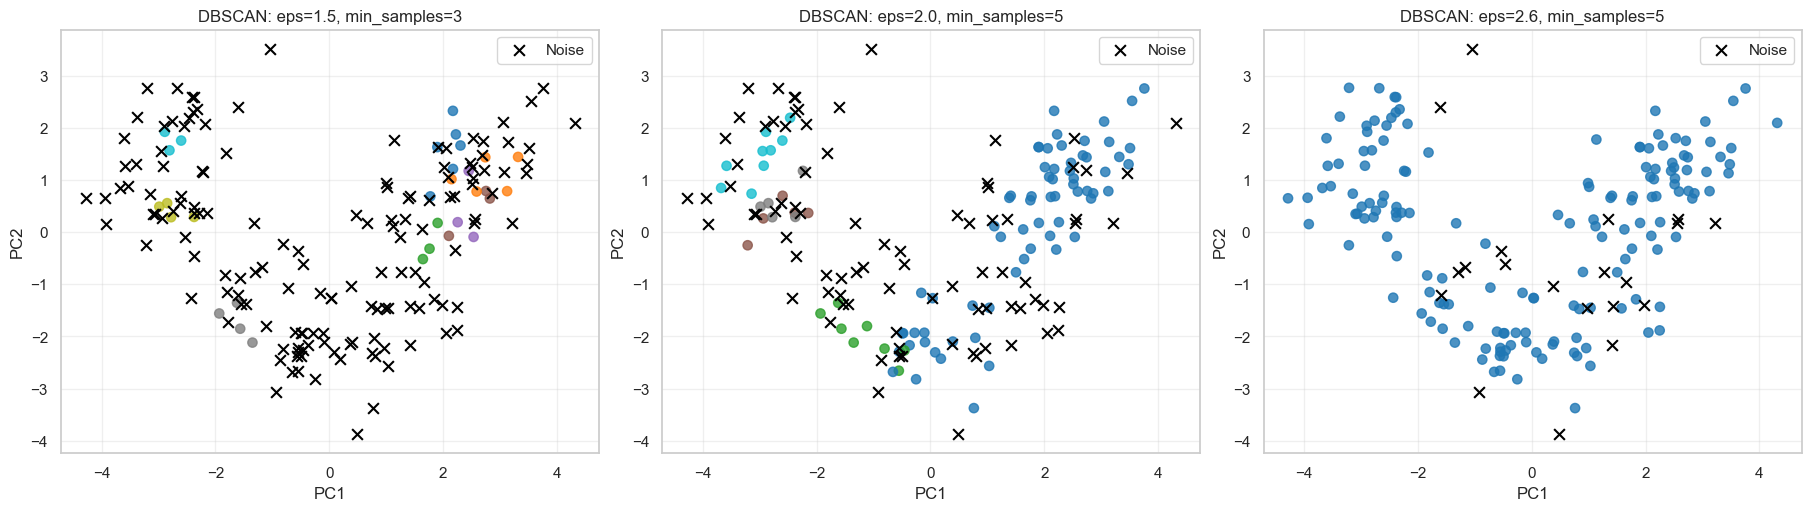

In [12]:
# Project DBSCAN labels onto PCA axes; label -1 means noise, shown separately with black x markers.
selected_dbscan = [(1.5, 3), (2.0, 5), (2.6, 5)]
fig, axes = plt.subplots(1, len(selected_dbscan), figsize=(18, 5), constrained_layout=True)

for ax, key in zip(axes, selected_dbscan):
    labels = dbscan_labels[key]
    regular = labels != -1
    ax.scatter(X_pca[regular, 0], X_pca[regular, 1], c=labels[regular], cmap="tab10", s=45, alpha=0.8)
    if (~regular).any():
        ax.scatter(X_pca[~regular, 0], X_pca[~regular, 1], c="black", marker="x", s=60, label="Noise")
    ax.set_title(f"DBSCAN: eps={key[0]}, min_samples={key[1]}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
plt.show()

**Reading the plots:** The black x markers are noise. At `eps=1.5, min_samples=3` most points are noise and the clusters are small, dense pockets. At `eps=2.0, min_samples=5` the main dense regions form clusters while points between and around them remain noise. At `eps=2.6, min_samples=5` the dense regions are joined into one cluster, and only the outer points (20) are noise. Because the plot is a 2D PCA projection, points that look close together in the plot may still be far apart in 13 dimensions.

### Evaluate and Compare Clustering Results

In [13]:
# Combine both algorithms so their cluster quality and noise handling are comparable.
comparison_results = pd.concat(
    [hierarchical_results, dbscan_results.drop(columns=["eps", "min_samples"], errors="ignore")],
    ignore_index=True,
)
comparison_results = comparison_results[
    ["algorithm", "parameter", "n_clusters", "noise_points", "silhouette_score", "homogeneity_score", "completeness_score"]
]

# Rank valid results by silhouette first and homogeneity second; NaN scores sort last.
comparison_results = comparison_results.sort_values(
    by=["silhouette_score", "homogeneity_score"], ascending=False, na_position="last"
).reset_index(drop=True)

display(comparison_results.round(4))
print("\nInterpretation guide:")
print("- Higher silhouette scores indicate better separation and cohesion.")
print("- Homogeneity is higher when each cluster contains mostly one known wine class.")
print("- Completeness is higher when each known wine class is assigned mostly to one cluster.")
print("- DBSCAN noise points are excluded from its silhouette calculation and from label-based metrics when appropriate.")

,algorithm,parameter,n_clusters,noise_points,silhouette_score,homogeneity_score,completeness_score
0,DBSCAN,"eps=2.0, min_samples=8",3,117,0.4360,0.8998,0.9320
1,DBSCAN,"eps=2.3, min_samples=8",2,52,0.3422,0.5166,0.9380
2,DBSCAN,"eps=1.5, min_samples=3",8,147,0.3311,1.0000,0.4319
3,DBSCAN,"eps=2.3, min_samples=5",2,42,0.3307,0.5345,0.9438
4,DBSCAN,"eps=1.8, min_samples=3",8,90,0.3116,1.0000,0.6225
5,Agglomerative,n_clusters=3,3,0,0.2774,0.7904,0.7825
6,Agglomerative,n_clusters=2,2,0,0.2670,0.4441,0.7745
7,DBSCAN,"eps=1.8, min_samples=5",7,118,0.2462,1.0000,0.5635
8,DBSCAN,"eps=2.0, min_samples=5",5,85,0.2405,0.5858,0.6056
9,Agglomerative,n_clusters=4,4,0,0.2258,0.7904,0.6490



Interpretation guide:
- Higher silhouette scores indicate better separation and cohesion.
- Homogeneity is higher when each cluster contains mostly one known wine class.
- Completeness is higher when each known wine class is assigned mostly to one cluster.
- DBSCAN noise points are excluded from its silhouette calculation and from label-based metrics when appropriate.


### Comparison and Conclusions

| | Agglomerative (Ward) | DBSCAN |
|---|---|---|
| Best setting | `n_clusters=3` | `eps=2.0`, `min_samples=8` (by silhouette) |
| Silhouette | 0.2774 | 0.4360 (on 61 non-noise points) |
| Homogeneity / Completeness | 0.7904 / 0.7825 | 0.8998 / 0.9320 (on non-noise points) |
| Points assigned to a cluster | 178 of 178 | 61 of 178 (117 noise) |
| Key parameter | Number of clusters, guided by the dendrogram | `eps` and `min_samples`, very sensitive |

**Comparison:** DBSCAN's top scores look higher, but they are computed only on the 61 points it kept, while Agglomerative scores cover all 178 wines. The scores are therefore not directly comparable. On full coverage, Agglomerative with 3 clusters recovers the three wine classes well (homogeneity and completeness near 0.78-0.79).

**Parameter influence:** For Agglomerative, increasing `n_clusters` beyond 3 lowers silhouette and completeness, and the dendrogram shows why: there are three clear main branches. For DBSCAN, small changes in `eps` move the result from all noise to one big cluster, and raising `min_samples` increases noise.

**Strengths and weaknesses**
- *Agglomerative:* Assigns every observation, gives an interpretable dendrogram, and worked well here. It requires choosing the number of clusters, its Ward linkage assumes compact groups, and it has no notion of outliers.
- *DBSCAN:* No cluster count is needed and it flags noise points explicitly. On this standardized 13-feature data, the density is not uniform enough for a single `eps`, so it either labels most points as noise or merges classes.

**Conclusion:** For this Wine dataset, Agglomerative clustering with `n_clusters=3` is the more reliable choice. DBSCAN is more useful for identifying unusual wines than for partitioning the whole dataset.